# 01 Preprocessing
Input: raw reads data/raw/fungut_forward_reads.qza, metadata data/raw/fungut_metadata.tsv

Output (processed_ignored/01_preprocessing/): primer-trimmed reads reads_trimmed.qza, cutadapt_stats.qza, primer check tables

## 0 setup

In [1]:
import os
import pandas as pd
from qiime2 import Visualization
import matplotlib.pyplot as plt

%matplotlib inline

In [2]:
raw_dir = '../data/raw'
out_dir = '../data/processed_ignored/01_preprocessing'
vis_dir = '../data/processed/01_preprocessing'

In [3]:
! ls

 01_preprocessing_jingxi.ipynb
 02_denoise_jingxi.ipynb
 04_OTU_clustering_Gwendolin.ipynb
'Addition of urbanity to metadata.ipynb'
'Alpha Diversity.ipynb'
'Clustering closed ref ITS.ipynb'
 Clustering.ipynb
'Quality Filtering.ipynb'
'Quality plot generation.ipynb'
'Taxonomic Classification.ipynb'
 Taxonomic_Classification_jingxi.ipynb
 metadata_distributions.ipynb
 try_taxanomy.ipynb


## 1 import data

In [4]:
! ls -l $raw_dir

total 2185760
-rw-r--r-- 1 jovyan jovyan  230686720 Oct 14 10:23 ITS_database.fasta
-rw-r--r-- 1 jovyan jovyan 1294892168 Oct 14 10:30 UNITE_public_19.02.2025.fasta
-rw-r--r-- 1 jovyan jovyan  712595535 Oct  2 15:24 fungut_forward_reads.qza
-rw-r--r-- 1 jovyan jovyan      18798 Oct  2 15:18 fungut_metadata.tsv


In [5]:
! echo 'Number of files in the directory is:' && ls $raw_dir| wc -l

Number of files in the directory is:
4


In [6]:
!unzip -l ../data/raw/fungut_forward_reads.qza | grep fastq | head -10

  6218883  2024-09-10 14:52   3638611d-1767-413b-9390-70ee3d78e4ff/data/ERR5327540_01_L001_R1_001.fastq.gz
  2734350  2024-09-10 14:52   3638611d-1767-413b-9390-70ee3d78e4ff/data/ERR5327531_01_L001_R1_001.fastq.gz
  3907977  2024-09-10 14:52   3638611d-1767-413b-9390-70ee3d78e4ff/data/ERR5327266_01_L001_R1_001.fastq.gz
  5596947  2024-09-10 14:52   3638611d-1767-413b-9390-70ee3d78e4ff/data/ERR5327415_01_L001_R1_001.fastq.gz
  4274543  2024-09-10 14:52   3638611d-1767-413b-9390-70ee3d78e4ff/data/ERR5327489_01_L001_R1_001.fastq.gz
  1981961  2024-09-10 14:52   3638611d-1767-413b-9390-70ee3d78e4ff/data/ERR5327284_01_L001_R1_001.fastq.gz
  4617752  2024-09-10 14:52   3638611d-1767-413b-9390-70ee3d78e4ff/data/ERR5327464_01_L001_R1_001.fastq.gz
  4880282  2024-09-10 14:52   3638611d-1767-413b-9390-70ee3d78e4ff/data/ERR5327562_01_L001_R1_001.fastq.gz
  3780841  2024-09-10 14:52   3638611d-1767-413b-9390-70ee3d78e4ff/data/ERR5327513_01_L001_R1_001.fastq.gz
  4387898  2024-09-10 14:52   3638611

In [7]:
!unzip -l ../data/raw/fungut_forward_reads.qza | grep -c fastq.gz

150


In [8]:
metadata_df = pd.read_csv(f'{raw_dir}/fungut_metadata.tsv', sep='\t', index_col=0)
metadata_df.sample(n=5)

,country_sample,state_sample,latitude_sample,longitude_sample,sex_sample,age_years_sample,height_cm_sample,weight_kg_sample,bmi_sample,diet_type_sample,ibd_sample,gluten_sample
ID,,,,,,,,,,,,
ERR5327326,Australia,ACT,-35.2,149.1,female,54.0,161.0,62.0,23.92,Omnivore,I do not have this condition,No
ERR5327349,Australia,NSW,-33.7,151.0,male,2.0,Not provided,9.0,Not provided,Omnivore,I do not have this condition,No
ERR5327343,Australia,QLD,-27.5,152.9,male,37.0,186.0,72.0,20.81,Omnivore,I do not have this condition,No
ERR5327266,USA,VA,38.9,-77.1,female,28.0,175.0,61.0,19.94,Omnivore,I do not have this condition,I do not eat gluten because it makes me feel bad
ERR5327355,Australia,NSW,-33.7,151.0,male,43.0,180.0,74.0,22.84,Omnivore,I do not have this condition,No


## 2 check qc

In [11]:
!qiime tools peek $raw_dir/fungut_forward_reads.qza

!qiime demux summarize \
  --i-data $raw_dir/fungut_forward_reads.qza \
  --o-visualization $vis_dir/demux_summary.qzv

UUID:        3638611d-1767-413b-9390-70ee3d78e4ff
Type:        SampleData[SequencesWithQuality]
Data format: SingleLanePerSampleSingleEndFastqDirFmt
Saved Visualization to: ../data/processed/01_preprocessing/demux_summary.qzv


In [12]:
Visualization.load(f"{vis_dir}/demux_summary.qzv")

<visualization: Visualization uuid: 0b8be0c9-8576-44f6-a328-c1a059ca5274>

In [13]:
!qiime tools export \
  --input-path $raw_dir/fungut_forward_reads.qza \
  --output-path $out_dir/exported

Exported ../data/raw/fungut_forward_reads.qza as SingleLanePerSampleSingleEndFastqDirFmt to directory ../data/processed_ignored/01_preprocessing/exported


checking the forward and reverse primer & visualization

In [14]:
%%bash
cd ../data/processed_ignored/01_preprocessing/exported
out=..
echo -e "sample\ttotal\twith_primer\tFWD\tFWD_rc\tREV" > $out/primer_counts.tsv
echo -e "sample\tposition\treads"                     > $out/primer_positions.tsv

for f in *.fastq.gz; do
  s=${f%%_*}
  zcat $f | awk -v s=$s -v out=$out '
    NR%4==2 {  # only read the sequence line
      n++
      p=index($0,"GCATCGATGAAGAACGCAGC"); if(p>0){h++; pos[p]++}
      if(index($0,"CTTGGTCATTTAGAGGAAGTAA")) a++
      if(index($0,"TTACTTCCTCTAAATGACCAAG")) b++
      if(index($0,"GCTGCGTTCTTCATCGATGC"))   c++
    }
    END {
      print s"\t"n"\t"h+0"\t"a+0"\t"b+0"\t"c+0 >> out"/primer_counts.tsv"   # +0 prints 0 instead of an empty field when nothing was found
      for(k in pos) print s"\t"k"\t"pos[k] >> out"/primer_positions.tsv"
    }'
done

echo "Reads with other primer orientations (all samples, expected ~0):"
awk -F'\t' 'NR>1{a+=$4; b+=$5; c+=$6} END{print "FWD:",a,"  FWD_rc:",b,"  REV:",c}' $out/primer_counts.tsv
true

Reads with other primer orientations (all samples, expected ~0):
FWD: 0   FWD_rc: 0   REV: 0


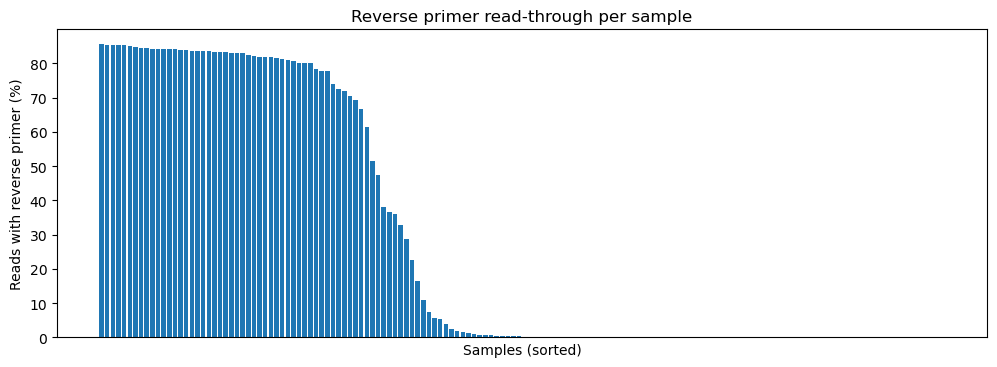

In [15]:
#read
counts = pd.read_csv(f'{out_dir}/primer_counts.tsv', sep='\t')

# count the percentage of reads contain primer in each sample
counts['percent'] = counts['with_primer'] / counts['total'] * 100

# from highest to lowest
counts = counts.sort_values('percent', ascending=False)

# bar plot
plt.figure(figsize=(12, 4))
plt.bar(counts['sample'], counts['percent'])
plt.xticks([])   # 150 sample names are too crowded to read
plt.xlabel('Samples (sorted)')
plt.ylabel('Reads with reverse primer (%)')
plt.title('Reverse primer read-through per sample')
plt.savefig(f'{vis_dir}/primer_percent_per_sample.png', dpi=200)
plt.show()

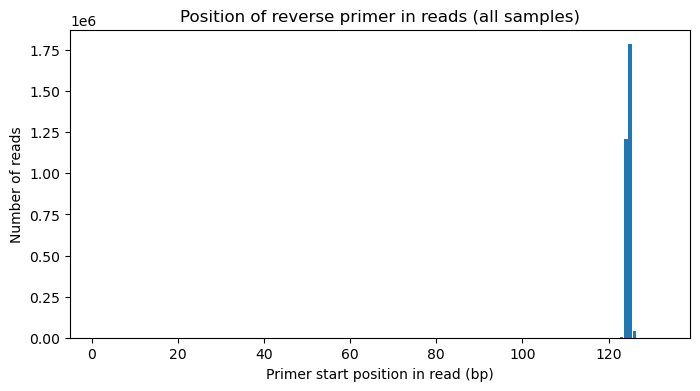

In [16]:
# read
pos = pd.read_csv(f'{out_dir}/primer_positions.tsv', sep='\t')

# find the counts in every position 
pos_total = pos.groupby('position')['reads'].sum()

# bar plot
plt.figure(figsize=(8, 4))
plt.bar(pos_total.index, pos_total.values)
plt.xlabel('Primer start position in read (bp)')
plt.ylabel('Number of reads')
plt.title('Position of reverse primer in reads (all samples)')
plt.savefig(f'{vis_dir}/primer_position.png', dpi=200)
plt.show()

## 3 cut the primer

In [17]:
!qiime cutadapt trim-single \
  --i-demultiplexed-sequences $raw_dir/fungut_forward_reads.qza \
  --p-adapter GCATCGATGAAGAACGCAGC \
  --p-minimum-length 50 \
  --p-cores 1 \
  --o-trimmed-sequences $out_dir/reads_trimmed.qza \
  --o-stats $out_dir/cutadapt_stats.qza

Saved SampleData[SequencesWithQuality] to: ../data/processed_ignored/01_preprocessing/reads_trimmed.qza
Saved ImmutableMetadata to: ../data/processed_ignored/01_preprocessing/cutadapt_stats.qza


quality plot after cut: The shortest read after trimming was 113 nt, and almost no reads were discarded.also the quality still looks good.

In [18]:
!qiime demux summarize \
  --i-data $out_dir/reads_trimmed.qza \
  --o-visualization $vis_dir/reads_trimmed_summary.qzv

Saved Visualization to: ../data/processed/01_preprocessing/reads_trimmed_summary.qzv


In [19]:
Visualization.load(f'{vis_dir}/reads_trimmed_summary.qzv')

<visualization: Visualization uuid: 50a80748-d73f-4e91-a000-4e0f57ffbea7>

check how much we cut 

In [22]:
!qiime metadata tabulate \
  --m-input-file $out_dir/cutadapt_stats.qza \
  --o-visualization $vis_dir/cutadapt_stats.qzv

Saved Visualization to: ../data/processed/01_preprocessing/cutadapt_stats.qzv


In [23]:
Visualization.load(f'{vis_dir}/cutadapt_stats.qzv')

<visualization: Visualization uuid: 0cb24b1b-0bb8-4c51-ac87-b0a0fb471d3c>